# Thí nghiệm 2: Lượng tử hóa encoder TinyCAE sang INT8

## Mục tiêu

Thí nghiệm chuyển encoder TinyCAE FP32 sang TensorFlow Lite INT8 bằng phương pháp post-training quantization. Toàn bộ toán tử, tensor đầu vào và tensor đầu ra được lượng tử hóa INT8. Chất lượng tái tạo của encoder INT8 được so sánh với đường cơ sở FP32 trên PC trước khi triển khai phần cứng.

## 1. Thiết lập thí nghiệm

Các đường dẫn tới model FP32, dữ liệu CIFAR-10, manifest chia tập và thư mục đầu ra được khai báo tập trung. Model sử dụng là checkpoint chính thức từ Thí nghiệm 1.

In [1]:
from pathlib import Path
import hashlib
import io
import json
import pickle
import tarfile

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 2026
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FP32_DIR = PROJECT_ROOT / 'models' / 'tinycae' / 'notebook_baseline'
INT8_DIR = PROJECT_ROOT / 'models' / 'tinycae' / 'int8'
MANIFEST_DIR = PROJECT_ROOT / 'manifests'
ARCHIVE_PATH = PROJECT_ROOT / 'data' / 'raw' / 'cifar-10-python.tar.gz'
SPLITS_PATH = PROJECT_ROOT / 'data' / 'splits' / 'cifar10_seed2026_indices.npz'
TFLITE_PATH = INT8_DIR / 'encoder_int8.tflite'
MODEL_MANIFEST_PATH = MANIFEST_DIR / 'model_manifest.json'

print('TensorFlow:', tf.__version__)
print('FP32 model directory:', FP32_DIR)
assert (FP32_DIR / 'encoder.keras').exists(), 'Chưa có encoder.keras từ notebook 01'
assert (FP32_DIR / 'decoder.keras').exists(), 'Chưa có decoder.keras từ notebook 01'

TensorFlow: 2.21.0
FP32 model directory: d:\projects\iot-final\models\tinycae\notebook_baseline


## 2. Nạp mô hình FP32

Encoder và decoder được nạp độc lập mà không biên dịch lại hàm mất mát. Kích thước tensor được xác minh: encoder nhận ảnh 32 × 32 × 3 và tạo latent 8 × 8 × 16; decoder thực hiện ánh xạ ngược về không gian ảnh.

In [2]:
encoder_fp32 = tf.keras.models.load_model(FP32_DIR / 'encoder.keras', compile=False)
decoder_fp32 = tf.keras.models.load_model(FP32_DIR / 'decoder.keras', compile=False)
print('Encoder:', encoder_fp32.input_shape, '->', encoder_fp32.output_shape)
print('Decoder:', decoder_fp32.input_shape, '->', decoder_fp32.output_shape)
assert encoder_fp32.input_shape == (None, 32, 32, 3)
assert encoder_fp32.output_shape == (None, 8, 8, 16)

Encoder: (None, 32, 32, 3) -> (None, 8, 8, 16)
Decoder: (None, 8, 8, 16) -> (None, 32, 32, 3)


## 3. Tập hiệu chỉnh lượng tử hóa

Tập representative gồm 500 ảnh lấy từ train theo manifest seed 2026. Tập test không tham gia hiệu chỉnh thang lượng tử, bảo đảm phép đánh giá cuối không bị rò rỉ thông tin. Ảnh calibration được chuẩn hóa về miền `[0,1]`, thống nhất với đầu vào khi huấn luyện.

In [3]:
def read_batch(archive, member_name):
    extracted = archive.extractfile(member_name)
    if extracted is None:
        raise RuntimeError(f'Không đọc được {member_name}')
    batch = pickle.load(extracted, encoding='bytes')
    planar = np.asarray(batch[b'data'], dtype=np.uint8)
    images = planar.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).copy()
    labels = np.asarray(batch[b'labels'], dtype=np.int64)
    return images, labels

with tarfile.open(ARCHIVE_PATH, 'r:gz') as archive:
    train_batches = [read_batch(archive, f'cifar-10-batches-py/data_batch_{i}') for i in range(1, 6)]
    test_images, test_labels = read_batch(archive, 'cifar-10-batches-py/test_batch')

all_train_images = np.concatenate([batch[0] for batch in train_batches], axis=0)
with np.load(SPLITS_PATH) as splits:
    calibration_indices = splits['calibration_indices'].copy()
    validation_indices = splits['validation_indices'].copy()

calibration_images = all_train_images[calibration_indices].astype(np.float32) / 255.0
validation_images = all_train_images[validation_indices].astype(np.float32) / 255.0
test_images_float = test_images.astype(np.float32) / 255.0
print('Calibration:', calibration_images.shape)
print('Validation:', validation_images.shape)
print('Test:', test_images_float.shape)
assert calibration_images.shape == (500, 32, 32, 3)

Calibration: (500, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Test: (10000, 32, 32, 3)


## 4. Chuyển đổi TensorFlow Lite INT8

Converter áp dụng `Optimize.DEFAULT`, representative dataset và tập toán tử `TFLITE_BUILTINS_INT8`. Kiểu dữ liệu inference đầu vào và đầu ra được đặt là `int8`, loại bỏ yêu cầu tensor float trong pipeline encoder trên vi điều khiển.

In [4]:
def representative_dataset():
    for image in calibration_images:
        yield [image[np.newaxis, ...].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(encoder_fp32)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()
INT8_DIR.mkdir(parents=True, exist_ok=True)
TFLITE_PATH.write_bytes(tflite_model)
print('Đã lưu:', TFLITE_PATH)
print('Kích thước:', len(tflite_model), 'byte')

INFO:tensorflow:Assets written to: C:\Users\vubao\AppData\Local\Temp\tmptjrqrhyf\assets


INFO:tensorflow:Assets written to: C:\Users\vubao\AppData\Local\Temp\tmptjrqrhyf\assets


Saved artifact at 'C:\Users\vubao\AppData\Local\Temp\tmptjrqrhyf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='rgb_input')
Output Type:
  TensorSpec(shape=(None, 8, 8, 16), dtype=tf.float32, name=None)
Captures:
  3225506050896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506051472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506050128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506051856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506053392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506053008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506053968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3225506052624: TensorSpec(shape=(), dtype=tf.resource, name=None)


d:\projects\iot-final\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Đã lưu: d:\projects\iot-final\models\tinycae\int8\encoder_int8.tflite
Kích thước: 9560 byte


## 5. Xác minh cấu trúc model TFLite

Interpreter được dùng để đọc metadata thực tế của model. Điều kiện hợp lệ gồm input và output `int8`, output `[1,8,8,16]`, tổng 1.024 phần tử latent và các scale lượng tử dương. Danh sách toán tử được lưu phục vụ cấu hình `MicroMutableOpResolver` trên ESP32.

In [5]:
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]
ops = [entry['op_name'] for entry in interpreter._get_ops_details()]

print('Input:', input_detail['shape'], input_detail['dtype'], input_detail['quantization'])
print('Output:', output_detail['shape'], output_detail['dtype'], output_detail['quantization'])
print('Operators:', ops)
assert input_detail['dtype'] == np.int8
assert output_detail['dtype'] == np.int8
assert tuple(output_detail['shape']) == (1, 8, 8, 16)
assert int(np.prod(output_detail['shape'])) == 1024
assert input_detail['quantization'][0] > 0
assert output_detail['quantization'][0] > 0

Input: [ 1 32 32  3] <class 'numpy.int8'> (0.003921568859368563, -128)
Output: [ 1  8  8 16] <class 'numpy.int8'> (0.005573478527367115, -7)
Operators: ['CONV_2D', 'DEPTHWISE_CONV_2D', 'CONV_2D', 'CONV_2D', 'DELEGATE']


d:\projects\iot-final\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 6. Phép lượng tử hóa đầu vào và giải lượng tử latent

Ảnh RGB888 được chuẩn hóa thành $x \in [0,1]$, sau đó lượng tử hóa theo $q=\operatorname{round}(x/s)+z$. Trong đó $s$ và $z$ lần lượt là scale và zero point lấy trực tiếp từ model. Latent INT8 được giải lượng tử bằng $x=(q-z)s$ trước khi đưa vào decoder FP32. Việc ép kiểu trực tiếp từ `uint8` sang `int8` không được sử dụng vì gây tràn số đối với giá trị lớn hơn 127.

In [6]:
input_scale, input_zero_point = input_detail['quantization']
output_scale, output_zero_point = output_detail['quantization']

def run_encoder_int8(image_float):
    quantized = np.round(image_float / input_scale + input_zero_point)
    quantized = np.clip(quantized, -128, 127).astype(np.int8)[np.newaxis, ...]
    interpreter.set_tensor(input_detail['index'], quantized)
    interpreter.invoke()
    latent_int8 = interpreter.get_tensor(output_detail['index']).copy()
    latent_float = (latent_int8.astype(np.float32) - output_zero_point) * output_scale
    return latent_int8, latent_float

sample = validation_images[0]
latent_fp32 = encoder_fp32.predict(sample[np.newaxis, ...], verbose=0)
latent_int8, latent_dequantized = run_encoder_int8(sample)
reconstruction_fp32 = decoder_fp32.predict(latent_fp32, verbose=0)[0]
reconstruction_int8 = decoder_fp32.predict(latent_dequantized, verbose=0)[0]
print('Latent INT8:', latent_int8.shape, latent_int8.dtype, latent_int8.nbytes, 'byte')

Latent INT8: (1, 8, 8, 16) int8 1024 byte


## 7. Kiểm tra trực quan FP32–INT8

Một ảnh validation được tái tạo theo hai nhánh: encoder FP32 và encoder INT8 kết hợp cùng decoder FP32. So sánh trực quan nhằm phát hiện sai lệch rõ rệt trước phép đánh giá toàn tập.

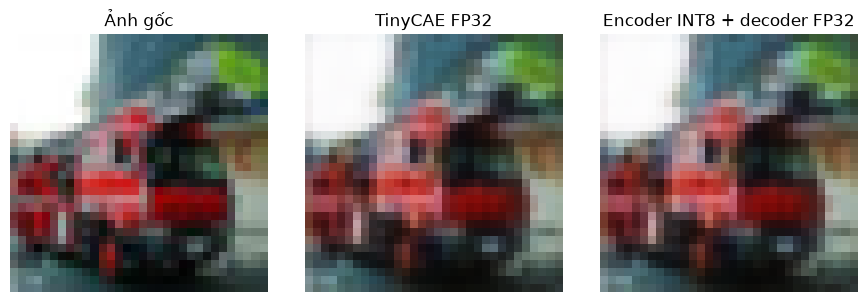

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for axis, image, title in zip(
    axes,
    [sample, reconstruction_fp32, reconstruction_int8],
    ['Ảnh gốc', 'TinyCAE FP32', 'Encoder INT8 + decoder FP32'],
):
    axis.imshow(np.clip(image, 0, 1))
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()

## 8. Đánh giá định lượng trên PC

Chế độ kiểm tra nhanh sử dụng 100 ảnh validation để xác minh pipeline. Đánh giá chính thức sử dụng toàn bộ 10.000 ảnh test và chỉ được thực hiện sau khi cấu hình model đã cố định. PSNR, SSIM và độ suy giảm INT8–FP32 được tính theo từng ảnh rồi lấy trung bình.

In [9]:
QUICK_RUN = False
evaluation_images = validation_images[:100] if QUICK_RUN else test_images_float

latents_fp32 = encoder_fp32.predict(evaluation_images, batch_size=128, verbose=0)
latents_int8_float = []
for number, image in enumerate(evaluation_images, start=1):
    _, latent_float = run_encoder_int8(image)
    latents_int8_float.append(latent_float[0])
    if number % 1000 == 0:
        print(f'INT8: {number}/{len(evaluation_images)}')
latents_int8_float = np.asarray(latents_int8_float, dtype=np.float32)

recon_fp32 = decoder_fp32.predict(latents_fp32, batch_size=128, verbose=0)
recon_int8 = decoder_fp32.predict(latents_int8_float, batch_size=128, verbose=0)
psnr_fp32 = tf.image.psnr(evaluation_images, recon_fp32, max_val=1.0).numpy()
ssim_fp32 = tf.image.ssim(evaluation_images, recon_fp32, max_val=1.0).numpy()
psnr_int8 = tf.image.psnr(evaluation_images, recon_int8, max_val=1.0).numpy()
ssim_int8 = tf.image.ssim(evaluation_images, recon_int8, max_val=1.0).numpy()

print(f'FP32 PSNR: {psnr_fp32.mean():.4f} dB | SSIM: {ssim_fp32.mean():.6f}')
print(f'INT8 PSNR: {psnr_int8.mean():.4f} dB | SSIM: {ssim_int8.mean():.6f}')
print(f'Chênh lệch PSNR: {(psnr_int8 - psnr_fp32).mean():.4f} dB')
print(f'Chênh lệch SSIM: {(ssim_int8 - ssim_fp32).mean():.6f}')

INT8: 1000/10000
INT8: 2000/10000
INT8: 3000/10000
INT8: 4000/10000
INT8: 5000/10000
INT8: 6000/10000
INT8: 7000/10000
INT8: 8000/10000
INT8: 9000/10000
INT8: 10000/10000
FP32 PSNR: 31.6128 dB | SSIM: 0.965454
INT8 PSNR: 30.6839 dB | SSIM: 0.959357
Chênh lệch PSNR: -0.9289 dB
Chênh lệch SSIM: -0.006097


## 9. Model manifest và kết quả đánh giá

Manifest lưu SHA-256, kích thước model, shape, dtype, scale, zero point, bố cục NHWC, số byte latent và danh sách toán tử. Các tham số lượng tử được trích xuất từ file TFLite thực tế, không sử dụng giá trị giả định.

In [10]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
manifest = {
    'model_id': 1,
    'encoder_file': TFLITE_PATH.relative_to(PROJECT_ROOT).as_posix(),
    'encoder_sha256': sha256_file(TFLITE_PATH),
    'encoder_bytes': TFLITE_PATH.stat().st_size,
    'input_shape': input_detail['shape'].astype(int).tolist(),
    'input_dtype': 'int8',
    'input_scale': float(input_scale),
    'input_zero_point': int(input_zero_point),
    'output_shape': output_detail['shape'].astype(int).tolist(),
    'output_dtype': 'int8',
    'output_scale': float(output_scale),
    'output_zero_point': int(output_zero_point),
    'layout': 'NHWC',
    'latent_bytes': 1024,
    'operators': ops,
    'calibration_images': 500,
    'calibration_seed': SEED,
}
MODEL_MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
metrics = {
    'quick_run': QUICK_RUN,
    'evaluation_images': len(evaluation_images),
    'fp32_psnr_db': float(psnr_fp32.mean()),
    'fp32_ssim': float(ssim_fp32.mean()),
    'int8_psnr_db': float(psnr_int8.mean()),
    'int8_ssim': float(ssim_int8.mean()),
    'delta_psnr_db': float((psnr_int8 - psnr_fp32).mean()),
    'delta_ssim': float((ssim_int8 - ssim_fp32).mean()),
}
(INT8_DIR / 'pc_evaluation.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(json.dumps(manifest, indent=2))
print(json.dumps(metrics, indent=2))

{
  "model_id": 1,
  "encoder_file": "models/tinycae/int8/encoder_int8.tflite",
  "encoder_sha256": "d46a8c3da4df0937128e9926d42619c8716fadec31c647d900187795d10af14d",
  "encoder_bytes": 9560,
  "input_shape": [
    1,
    32,
    32,
    3
  ],
  "input_dtype": "int8",
  "input_scale": 0.003921568859368563,
  "input_zero_point": -128,
  "output_shape": [
    1,
    8,
    8,
    16
  ],
  "output_dtype": "int8",
  "output_scale": 0.005573478527367115,
  "output_zero_point": -7,
  "layout": "NHWC",
  "latent_bytes": 1024,
  "operators": [
    "CONV_2D",
    "DEPTHWISE_CONV_2D",
    "CONV_2D",
    "CONV_2D",
    "DELEGATE"
  ],
  "calibration_images": 500,
  "calibration_seed": 2026
}
{
  "quick_run": false,
  "evaluation_images": 10000,
  "fp32_psnr_db": 31.612825393676758,
  "fp32_ssim": 0.9654542803764343,
  "int8_psnr_db": 30.683940887451172,
  "int8_ssim": 0.9593572020530701,
  "delta_psnr_db": -0.9288867115974426,
  "delta_ssim": -0.006097087170928717
}


## 10. Tiêu chí hợp lệ

- Input và output đều `int8`.
- Output `[1, 8, 8, 16]` và latent đúng 1.024 byte.
- Không có toán tử float/flex trong danh sách operators.
- Ảnh INT8 tái tạo hợp lệ.
- Suy giảm PSNR/SSIM được ghi lại và chấp nhận được.

Các tiêu chí trên xác nhận encoder đủ điều kiện chuyển sang giai đoạn tạo vector tham chiếu và triển khai TensorFlow Lite Micro trên ESP32.